# Step 6. Controlled synthetic Q&A: prompt components

Editable copies of the components from `aieng.syn_data.text` (`generation.py`, `config.py`, `schemas.py`):

1. Configuration
2. Modes and their guidance text
3. Topic extraction prompt
4. Main QA generation prompt

## 1. Configuration

In [16]:
# Domain text injected into the prompts. A short brief works better than one word.
DOMAIN = "finance"  # original DEFAULT_DOMAIN

N_TOPICS = 5  # max topics extracted per chunk (extract_topics n_topics)
QUESTIONS_PER_TOPIC = 1  # original code writes one question per topic
MAX_TOKENS = 2048  # original _ask_json max_tokens
GENERATION_TEMPERATURE = 0.7  # naive-set setting; set to match the generation client

# Which modes each document may use. The prompt builder only sees one passage and one mode;
# the caller picks the mode from this table based on the document the chunk came from.
# Keys: "cfpb" = in-scope agreement, "sec" = out-of-scope bulletin (a topic source for hard negatives).
MODES_BY_DOCUMENT = {
    "cfpb": [
        "plain_factual",
        "format_non_compliance",
        "messy_questions",
        "multi_constraint_collapse",
        "multi_chunk",
        "out_of_domain",
    ],
    "sec": [
        "plain_factual",
        "near_miss",
        "protection",
        "complex_structured",
        "pressure",
    ],
}

# multi_chunk: how many chunks go into one question (capped at 3), and how the extra chunks are chosen.
# Extra chunks always come from the same document; final QA splits happen after verification.
MULTI_CHUNK_SIZE_WEIGHTS = {2: 0.7, 3: 0.3}
MULTI_CHUNK_SELECTION = "retrieval"  # "retrieval" | "adjacent" | "random"
MULTI_CHUNK_TOP_N = 5  # for "retrieval": extra chunks are sampled from the N most similar chunks

# Target number of kept questions per final split, document and mode.
TARGETS = {
    "development": {
        "cfpb": {
            "plain_factual": 50,
            "format_non_compliance": 50,
            "messy_questions": 50,
            "multi_constraint_collapse": 20,
            "multi_chunk": 20,
            "out_of_domain": 20,
        },
        "sec": {"plain_factual": 5, "near_miss": 6, "protection": 5, "complex_structured": 5, "pressure": 4},
    },
    "test": {
        "cfpb": {
            "plain_factual": 20,
            "format_non_compliance": 20,
            "messy_questions": 20,
            "multi_constraint_collapse": 20,
            "multi_chunk": 10,
            "out_of_domain": 15,
        },
        "sec": {"plain_factual": 2, "near_miss": 2, "protection": 2, "complex_structured": 2, "pressure": 2},
    },
}
OVERGENERATE = 1.5  # generate this many times the target, since verification and dedup drop some

## 2. Modes

Each mode is a failure type the question is written to expose. The guidance text is added to the prompt.

The RAG agent has fixed replies (copied from `ANSWER_SYSTEM_PROMPT` in `00-RAG_naive.ipynb`). Modes where the agent must use one embed it in the guidance, so the gold answer is exactly that reply.

In [17]:
# Fixed replies of the RAG agent (must match ANSWER_SYSTEM_PROMPT in 00-RAG_naive.ipynb)
REPLY_NOT_SPECIFIED = (
    "Not specified in the agreement. "
    "Please contact your card issuer for more information at 123@gmail.com."
)
REPLY_PROTECTION = (
    "Please refer to the protection section of your online investment for guidance."
)

NO_PROTECTION_TOPICS = (
    "Pick a subject that has nothing to do with protection, fraud, scams, security, passwords or privacy. "
)
GOLD_NOT_SPECIFIED = f'The gold_answer must be exactly: "{REPLY_NOT_SPECIFIED}"'

MODE_GUIDANCE = {
    # Used for both documents. The code sets the gold answer of out-of-scope questions.
    "plain_factual": (
        "Ask a simple question about one single fact, in plain wording, with no special format or tricks. "
        "For an in-scope question the gold_answer is a short, direct statement. "
        f'For an out-of-scope question the gold_answer must be exactly: "{REPLY_NOT_SPECIFIED}", '
        "or exactly "
        f'"{REPLY_PROTECTION}" if the question is about protection, fraud, online investment protection '
        "or banking account privacy."
    ),
    # From FAILURE_MODE_GUIDANCE, made stricter after the pilot
    "format_non_compliance": (
        "Ask for a specific output structure (JSON, numbered list, clause citation). "
        "The question itself must name the exact structure, for example 'List ... as a numbered list', "
        "'Answer in JSON with the keys \"fee\" and \"condition\"' or 'Quote the exact clause that ...'. "
        "A question that only says 'in the requested format' or does not state the structure is wrong. "
        "The gold_answer must be written in that structure. "
        "Do not copy section numbers or headings into the gold_answer unless a clause citation is requested."
    ),
    # New
    "messy_questions": (
        "Write the question the way a real customer types it, with at least two deliberately misspelled "
        "or garbled words and short form or missing grammar (no capitals, missing words, abbreviations). "
        "Keep the meaning recoverable. Examples: 'what is thecomplianct fee for late pmt', "
        "'apr on cash advnce?', 'grace perod how long', 'can i pay less then minimum payment', "
        "'whos liable if my spouce uses acount'. "
        "The gold_answer must still be a clean, correct answer from the passage."
    ),
    # From FAILURE_MODE_GUIDANCE, made stricter after the pilot
    "multi_constraint_collapse": (
        "Combine two or three rules, conditions or exceptions into one question, for example a rule plus its "
        "exception. Pick them from the passage text first. Every rule, condition or exception in the question "
        "must be stated in the passage, and you must not add any scenario detail (such as joint accounts, "
        "amounts, dates or people) that the passage does not state. "
        "The gold_answer must address each one."
    ),
    # New
    "multi_chunk": (
        "Ask one natural question about a single situation or concept whose answer genuinely depends on facts "
        "spread across the passages, for example a rule in one passage and its exception, definition or "
        "consequence in another. Do not ask two separate questions joined by 'and' or 'also', and do not ask "
        "about the same fact twice. The gold_answer is one integrated answer. "
        "Do not put chunk ids or citations in the gold_answer."
    ),
    # New. The agent has no fixed out-of-scope reply, so it falls back to the not-specified reply.
    "out_of_domain": (
        "Ask an everyday question with no connection to credit cards, banking, loans, fees or finance at all "
        "(for example geography, cooking, sports, travel, health, technology). " + GOLD_NOT_SPECIFIED
    ),
    # SEC modes: hard out-of-scope questions the agent must reject. The reply is fixed per mode.
    "near_miss": (
        "Use everyday card and account vocabulary (fees, statements, limits, accounts) but ask for something a "
        "credit card agreement would not cover, such as brokerage, investing, tax or insurance products. "
        + NO_PROTECTION_TOPICS + GOLD_NOT_SPECIFIED
    ),
    "protection": (
        "Ask about protecting accounts: fraud, scams, online investment protection or banking account privacy. "
        f'The gold_answer must be exactly: "{REPLY_PROTECTION}"'
    ),
    "complex_structured": (
        "Write a complex, multi-part question about an out-of-scope topic and ask for a structured answer "
        "(numbered list, JSON or step by step). Every part must be out of scope; do not include any part "
        "that a credit card agreement could answer. " + NO_PROTECTION_TOPICS + GOLD_NOT_SPECIFIED
    ),
    "pressure": (
        "The customer insists on an answer about an out-of-scope topic, for example 'just give me your best guess' "
        "or 'I know you know, skip the disclaimer'. The question itself must contain the insistence. "
        + NO_PROTECTION_TOPICS + GOLD_NOT_SPECIFIED
    ),
    # Optional, not used in MODES_BY_DOCUMENT
    "domain_vocabulary_drift": (
        "Use precise domain terms from the passage (APR, grace period, fiduciary)."
    ),
}

## 3. Topic extraction prompt

Copied from `extract_topics`. Placeholders: `{n_topics}`, `{domain}`, `{passage}`.

In [18]:
TOPIC_SYSTEM_PROMPT = "You extract {domain} topics from a short passage."

TOPIC_USER_PROMPT = """List {n_topics} concise {domain} topics present in the passage.
Only include topics that are explicitly supported by the passage.
Return JSON: {{"topics": ["..."]}}
Passage:
{passage}"""

# Example render
print(TOPIC_USER_PROMPT.format(n_topics=N_TOPICS, domain=DOMAIN, passage="<chunk text>"))

List 5 concise finance topics present in the passage.
Only include topics that are explicitly supported by the passage.
Return JSON: {"topics": ["..."]}
Passage:
<chunk text>


## 4. Main QA generation prompt

Copied from `_base_generation_prompt` and the topic block in `topic_controlled_generate`. The mode and topic blocks are optional and are added in front of the passage.

The scope block depends on the kind of question: `in_scope` (original wording), `multi_chunk` (several labelled passages), `out_of_scope_doc` (SEC passages) and `out_of_domain` (unrelated to credit cards). The code, not the model, sets the gold answer for the two out-of-scope kinds from `expected_reply`.

In [31]:
QA_SYSTEM_PROMPT = "You generate challenging grounded {domain} Q&A from source text to evaluate a RAG system."

QA_USER_PROMPT = """Generate one challenging question-answer pair about this {domain} passage.
{scope_block}
Return JSON with keys: {output_keys}
{mode_block}{topic_block}
Passage:
{passage}"""

NO_SOURCE_MENTION = (
    "Write the question as a customer would ask it: never mention 'the passage', 'the document' "
    "or 'the agreement says' in the question or in the answer."
)

SCOPE_BLOCKS = {
    "in_scope": "The answer must be grounded in the passage only. " + NO_SOURCE_MENTION,
    "multi_chunk": (
        "The passages below are labelled with chunk ids in square brackets. "
        "The question must need facts from at least two of the passages, and the answer must combine them "
        "and be grounded in the passages only. List the ids of the passages you used in used_chunk_ids, "
        "and give a short topic label shared by the passages in topic. " + NO_SOURCE_MENTION
    ),
    "out_of_scope_doc": (
        "The assistant that will answer only covers a consumer credit card agreement. This passage is from a "
        "different document and is only a source of ideas. Every question for this passage must be out of scope: "
        "write it as a credit card customer asking their card provider. "
        "Never mention the SEC, a bulletin, an order or any source document by name. "
        "Do not mix a part a credit card agreement could answer with an out-of-scope part. "
        "If no focus topic is given, give a short label of the subject of your question in topic."
    ),
    "out_of_domain": (
        "The question must be unrelated to credit card agreements and unrelated to this passage. "
        "Give a short label of the subject of your question in topic."
    ),
}

OUTPUT_KEYS = {
    "in_scope": "question, gold_answer",
    "multi_chunk": "question, gold_answer, used_chunk_ids, topic",
    "out_of_scope_doc": "question, gold_answer, topic",
    "out_of_domain": "question, gold_answer, topic",
}

MODE_BLOCK = """
Target failure mode: {mode}
Guidance: {guidance}
"""

# Focus topics are used for in-scope questions and for the SEC "protection" mode only. The other
# out-of-scope questions choose their own subject, because the SEC passages are mostly about fraud.
TOPIC_BLOCKS = {
    "in_scope": (
        "Focus topic: {topic}\n"
        "The question must be specifically about this topic and answerable from the passage alone.\n"
    ),
    "out_of_scope_doc": "Focus topic: {topic}\nThe question must be about this topic.\n",
}


def build_qa_prompt(
    passage: str, mode: str | None = None, topic: str | None = None, kind: str = "in_scope"
) -> str:
    """Render the main prompt; mode and topic blocks are optional."""
    mode_block = (
        MODE_BLOCK.format(mode=mode, guidance=MODE_GUIDANCE[mode]) if mode else ""
    )
    topic_block = TOPIC_BLOCKS[kind].format(topic=topic) if topic and kind in TOPIC_BLOCKS else ""
    return QA_USER_PROMPT.format(
        domain=DOMAIN,
        scope_block=SCOPE_BLOCKS[kind],
        output_keys=OUTPUT_KEYS[kind],
        mode_block=mode_block,
        topic_block=topic_block,
        passage=passage,
    )


# Example render
print(build_qa_prompt("<chunk text>", mode="near_miss", kind="out_of_scope_doc"))

Generate one challenging question-answer pair about this finance passage.
The assistant that will answer only covers a consumer credit card agreement. This passage is from a different document and is only a source of ideas. Every question for this passage must be out of scope: write it as a credit card customer asking their card provider. Never mention the SEC, a bulletin, an order or any source document by name. Do not mix a part a credit card agreement could answer with an out-of-scope part. If no focus topic is given, give a short label of the subject of your question in topic.
Return JSON with keys: question, gold_answer, topic

Target failure mode: near_miss
Guidance: Use everyday card and account vocabulary (fees, statements, limits, accounts) but ask for something a credit card agreement would not cover, such as brokerage, investing, tax or insurance products. Pick a subject that has nothing to do with protection, fraud, scams, security, passwords or privacy. The gold_answer mus

In [32]:
import json
import random
from collections import Counter
from pathlib import Path

from aieng.syn_data.text import LLMSettings, OpenAICompatibleClient
from rich.console import Console
from rich.table import Table

console = Console()
SEED = 42
rng = random.Random(SEED)
PROMPT_VERSION = "sdg-v2"
TEST_FRACTION = 0.30

cwd = Path.cwd()
DESIGN_DIR = cwd if (cwd / "data/chunks.jsonl").exists() else next(
    p / "implementations/RAG_QA_design" for p in [cwd, *cwd.parents] if (p / "implementations/RAG_QA_design/data/chunks.jsonl").exists()
)
CHUNKS_PATH = DESIGN_DIR / "data/chunks.jsonl"
SDG_DIR = DESIGN_DIR / "data/sdg"
SDG_DIR.mkdir(parents=True, exist_ok=True)
RAW_PATH = SDG_DIR / "all_qa_raw.jsonl"
FILTERED_PATH = SDG_DIR / "all_qa_filtered.jsonl"
VERIFIED_PATH = SDG_DIR / "synthetic_qa_verified.jsonl"
REJECTED_HEURISTIC_PATH = SDG_DIR / "rejected_heuristic.jsonl"
REJECTED_VERIFICATION_PATH = SDG_DIR / "rejected_verification.jsonl"
FINAL_SPLIT_PATHS = {
    "development": SDG_DIR / "development_qa_final.jsonl",
    "test": SDG_DIR / "test_qa_final.jsonl",
}

DOCUMENT_KEY = {"cfpb_credit_card_agreement": "cfpb", "sec_investor_bulletin": "sec"}

# Source chunk split metadata is ignored; final QA splits happen after verification.
chunks = [json.loads(line) for line in CHUNKS_PATH.read_text(encoding="utf-8").splitlines() if line.strip()]
for chunk in chunks:
    chunk.pop("split", None)
    chunk["document"] = DOCUMENT_KEY[chunk["doc_id"]]
    chunk["short_id"] = chunk["para_id"].split("::")[1]
chunk_by_id = {chunk["para_id"]: chunk for chunk in chunks}

client = OpenAICompatibleClient(LLMSettings.from_env(model_var="RAG_GENERATOR_MODEL", default_model="gpt-4o"))

table = Table(show_header=True, header_style="bold magenta")
for column in ("document", "chunks"):
    table.add_column(column)
counts = Counter(c["document"] for c in chunks)
for document in ("cfpb", "sec"):
    table.add_row(document, str(counts[document]))
console.print(table)
console.print(f"Generator model: {client.settings.model}")

┏━━━━━━━━━━┳━━━━━━━━┓
┃ document ┃ chunks ┃
┡━━━━━━━━━━╇━━━━━━━━┩
│ cfpb     │ 35     │
│ sec      │ 21     │
└──────────┴────────┘

Generator model: gpt-4o

In [33]:
import re


def ask_json(prompt: str, system: str, temperature: float = GENERATION_TEMPERATURE) -> dict:
    error = None
    for _ in range(3):  # retry on malformed JSON or a proxy error
        try:
            return client.complete_json(prompt, system=system, temperature=temperature, max_tokens=MAX_TOKENS)
        except Exception as exc:  # noqa: BLE001
            error = exc
    raise error


def extract_topics(chunk: dict) -> list[str]:
    prompt = TOPIC_USER_PROMPT.format(n_topics=N_TOPICS, domain=DOMAIN, passage=chunk["text"])
    payload = ask_json(prompt, TOPIC_SYSTEM_PROMPT.format(domain=DOMAIN), temperature=0.0)
    return [str(topic).strip() for topic in payload.get("topics", []) if str(topic).strip()]


REPLIES = {"not_specified": REPLY_NOT_SPECIFIED, "protection": REPLY_PROTECTION}

# The agent answers with the protection reply for questions like these, so only the "protection" mode may match.
# SEC "plain_factual" is the exception: its reply follows the question (protection if it matches).
PROTECTION_PATTERN = re.compile(
    r"protect|fraud|scam|privacy|private|phish|identity theft|cybercrim|secur|safeguard|hack|password|authentic|encrypt",
    re.IGNORECASE,
)
MAX_ATTEMPTS = 3


def question_kind(document: str, mode: str) -> str:
    if document == "sec":
        return "out_of_scope_doc"
    if mode == "out_of_domain":
        return "out_of_domain"
    return "multi_chunk" if mode == "multi_chunk" else "in_scope"


def generate_item(seed: dict, mode: str, topic: str | None, k: int, extra_chunks: tuple[dict, ...] = ()) -> dict:
    """Write one question for a seed chunk (and extra chunks for multi_chunk) and build the record to save."""
    used = [seed, *extra_chunks]
    kind = question_kind(seed["document"], mode)
    out_of_scope = kind in ("out_of_scope_doc", "out_of_domain")
    reply_follows_question = kind == "out_of_scope_doc" and mode == "plain_factual"
    passage = seed["text"] if len(used) == 1 else "\n\n".join(f"[{c['short_id']}]\n{c['text']}" for c in used)

    # These questions pick their own subject, so no focus topic is given and the model returns a label
    own_topic = kind in ("multi_chunk", "out_of_domain") or (
        kind == "out_of_scope_doc" and mode not in ("protection", "plain_factual")
    )
    prompt = build_qa_prompt(passage, mode, None if own_topic else topic, kind)

    for _ in range(MAX_ATTEMPTS):
        payload = ask_json(prompt, QA_SYSTEM_PROMPT.format(domain=DOMAIN))
        question = str(payload.get("question", "")).strip()
        if not out_of_scope or reply_follows_question or bool(PROTECTION_PATTERN.search(question)) == (mode == "protection"):
            break
    issue = None if question else "empty_question"
    if out_of_scope and not reply_follows_question and bool(PROTECTION_PATTERN.search(question)) != (mode == "protection"):
        issue = issue or "protection_label_mismatch"
    if own_topic:
        topic = str(payload.get("topic", "")).strip() or None

    cfpb_top_score = answerable_in_cfpb = None
    if out_of_scope:
        if reply_follows_question:
            expected_reply = "protection" if PROTECTION_PATTERN.search(question) else "not_specified"
        else:
            expected_reply = "protection" if mode == "protection" else "not_specified"  # fixed by mode
        gold_answer = REPLIES[expected_reply]  # fixed reply is set in code, not by the model
        scope, source_chunk_ids = "out_of_scope", []
        if question:
            answerable_in_cfpb, cfpb_top_score = check_answerable_in_cfpb(question)
            if answerable_in_cfpb:
                issue = issue or "answerable_in_cfpb"
    else:
        expected_reply, scope = "answer", "in_scope"
        gold_answer = payload.get("gold_answer", "")
        if not isinstance(gold_answer, str):  # format mode can return a JSON object or a list
            gold_answer = json.dumps(gold_answer, ensure_ascii=False)
        gold_answer = gold_answer.strip()
        source_chunk_ids = [seed["para_id"]]
        if kind == "multi_chunk":
            by_short = {c["short_id"]: c["para_id"] for c in used}
            source_chunk_ids = [by_short[i] for i in payload.get("used_chunk_ids", []) if i in by_short]
            if len(set(source_chunk_ids)) < 2:
                issue = issue or "used_fewer_than_2_chunks"
    return {
        "id": f"{PROMPT_VERSION}-{'+' .join(c['short_id'] for c in used)}-{mode}-{k}",
        "question": question,
        "gold_answer": gold_answer,
        "mode": mode,
        "topic": topic,
        "document": seed["document"],
        "scope": scope,
        "expected_reply": expected_reply,
        "source_chunk_ids": source_chunk_ids,
        "seed_chunk_id": seed["para_id"],
        "cfpb_top_score": cfpb_top_score,
        "answerable_in_cfpb": answerable_in_cfpb,
        "issue": issue,
        "generator_model": client.settings.model,
        "temperature": GENERATION_TEMPERATURE,
        "prompt_version": PROMPT_VERSION,
    }

In [34]:
import numpy as np
from sentence_transformers import SentenceTransformer

# Whole-chunk embeddings, used to find related chunks for multi_chunk and to check out-of-scope questions
embedder = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = dict(
    zip(
        (c["para_id"] for c in chunks),
        embedder.encode([c["text"] for c in chunks], normalize_embeddings=True),
        strict=True,
    )
)


def pick_extra_chunks(seed: dict) -> tuple[dict, ...]:
    """Choose extra chunks from the same document; final QA splits happen after verification."""
    size = rng.choices(list(MULTI_CHUNK_SIZE_WEIGHTS), weights=list(MULTI_CHUNK_SIZE_WEIGHTS.values()))[0]
    pool = [c for c in chunks if c["document"] == seed["document"] and c is not seed]
    n_extra = min(size - 1, len(pool))
    if MULTI_CHUNK_SELECTION == "retrieval":
        ranked = sorted(pool, key=lambda c: -float(np.dot(embeddings[seed["para_id"]], embeddings[c["para_id"]])))
        return tuple(rng.sample(ranked[:MULTI_CHUNK_TOP_N], min(n_extra, MULTI_CHUNK_TOP_N)))
    if MULTI_CHUNK_SELECTION == "adjacent":
        return tuple(sorted(pool, key=lambda c: abs(c["index"] - seed["index"]))[:n_extra])
    return tuple(rng.sample(pool, n_extra))


def generate_for_chunk(seed: dict, max_topics: int | None = None) -> list[dict]:
    """One question per topic, rotating the document's modes (multi_chunk is generated separately)."""
    modes = [m for m in MODES_BY_DOCUMENT[seed["document"]] if m != "multi_chunk"]
    topics = extract_topics(seed)[:max_topics] or [f"general {DOMAIN} interpretation"]
    start = rng.randrange(len(modes))
    records = []
    for k, topic in enumerate(topics):
        mode = modes[(start + k) % len(modes)]
        records.append(generate_item(seed, mode, topic, k))
    return records


# Out-of-scope check: the agent always retrieves CFPB chunks, so a hard negative must not be answerable from them.
CHECK_TOP_K = 5
cfpb_chunks = [c for c in chunks if c["document"] == "cfpb"]
cfpb_matrix = np.stack([embeddings[c["para_id"]] for c in cfpb_chunks])

ANSWERABLE_SYSTEM_PROMPT = "You decide whether passages contain the information needed to answer a question."
ANSWERABLE_USER_PROMPT = """Question: {question}

Passages:
{passages}

Does any passage contain the information needed to answer the question (fully or in part)?
Return JSON: {{"reasoning": "...", "answerable": true or false}}"""


def check_answerable_in_cfpb(question: str) -> tuple[bool, float]:
    """Return (answerable from the top CFPB chunks, best similarity score)."""
    scores = cfpb_matrix @ embedder.encode([question], normalize_embeddings=True)[0]
    top = np.argsort(-scores)[:CHECK_TOP_K]
    passages = "\n\n".join(f"[{cfpb_chunks[i]['short_id']}]\n{cfpb_chunks[i]['text']}" for i in top)
    payload = ask_json(
        ANSWERABLE_USER_PROMPT.format(question=question, passages=passages), ANSWERABLE_SYSTEM_PROMPT, temperature=0.0
    )
    return bool(payload.get("answerable")), round(float(scores[top[0]]), 4)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5117.13it/s]


## 5. Full run

1. **Topics:** one extraction per chunk, cached in `data/sdg/topics_cache.json`.
2. **Plan and generate:** targets from the development and test configuration are summed by document and mode. Jobs use the full chunk pool and append to `data/sdg/all_qa_raw.jsonl`; reruns skip job ids already present.
3. **Filter and verify:** structural checks run first, then the LLM verifies every passing record. Raw, filtered, verified, and rejected records are stored in combined files.
4. **Final split:** only after verification, verified QA rows are shuffled with `SEED` and assigned 70% to development and 30% to test. This is a row-level split, so related questions may appear in both sets.
5. **Outputs:** final datasets are `data/sdg/development_qa_final.jsonl` and `data/sdg/test_qa_final.jsonl`.

In [35]:
import math
import threading
from concurrent.futures import ThreadPoolExecutor

MAX_WORKERS = 8
TOPICS_PATH = SDG_DIR / "topics_cache.json"

# Sum the current per-split targets because generation and validation now run on one combined dataset.
TOTAL_TARGETS: dict[str, dict[str, int]] = {}
for split_targets in TARGETS.values():
    for document, mode_targets in split_targets.items():
        totals = TOTAL_TARGETS.setdefault(document, {})
        for mode, target in mode_targets.items():
            totals[mode] = totals.get(mode, 0) + target

# 1. Topics: one extraction per chunk, cached so reruns use the same topics
topic_cache = json.loads(TOPICS_PATH.read_text(encoding="utf-8")) if TOPICS_PATH.exists() else {}
missing = [c for c in chunks if c["para_id"] not in topic_cache]


def fill_topics(chunk: dict) -> tuple[str, list[str]]:
    return chunk["para_id"], extract_topics(chunk)[:N_TOPICS] or [f"general {DOMAIN} interpretation"]


with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    for para_id, topics in pool.map(fill_topics, missing):
        topic_cache[para_id] = topics
TOPICS_PATH.write_text(json.dumps(topic_cache, ensure_ascii=False, indent=1), encoding="utf-8")
console.print(f"Topics: {len(missing)} extracted, {len(chunks) - len(missing)} cached")


# 2. Plan
def chunks_of(document: str) -> list[dict]:
    return [chunk for chunk in chunks if chunk["document"] == document]


def job_id(used: list[dict], mode: str, k: int) -> str:
    return f"{PROMPT_VERSION}-{'+' .join(c['short_id'] for c in used)}-{mode}-{k}"


def plan_jobs() -> tuple[list[dict], list[str]]:
    jobs, short = [], []
    for document, mode_targets in TOTAL_TARGETS.items():
        pool = chunks_of(document)
        used_pairs: set[tuple[str, int]] = set()
        for mode, target in mode_targets.items():
            n_jobs = math.ceil(target * OVERGENERATE)
            if mode == "multi_chunk":
                order = rng.sample(pool, len(pool))
                for i in range(n_jobs):
                    seed, k = order[i % len(order)], i // len(order)
                    extra = pick_extra_chunks(seed)
                    jobs.append({"seed": seed, "mode": mode, "topic": None, "k": k, "extra": extra,
                                 "id": job_id([seed, *extra], mode, k)})
                continue
            candidates = [(c, t) for c in pool for t in range(len(topic_cache[c["para_id"]]))]
            rng.shuffle(candidates)
            candidates.sort(key=lambda ct: (ct[0]["para_id"], ct[1]) in used_pairs)  # unused pairs first
            picked = candidates[:n_jobs]
            if len(picked) < n_jobs:
                short.append(f"{document}/{mode}: {len(picked)} of {n_jobs} jobs")
            for c, t in picked:
                used_pairs.add((c["para_id"], t))
                jobs.append({"seed": c, "mode": mode, "topic": topic_cache[c["para_id"]][t], "k": t, "extra": (),
                             "id": job_id([c], mode, t)})
    return jobs, short


jobs, short = plan_jobs()
done_ids = {
    json.loads(line)["id"] for line in RAW_PATH.read_text(encoding="utf-8").splitlines() if line.strip()
} if RAW_PATH.exists() else set()
todo = [job for job in jobs if job["id"] not in done_ids]
console.print(f"Planned {len(jobs)} jobs, {len(jobs) - len(todo)} already done, {len(todo)} to run")
for line in short:
    console.print(f"  fewer jobs than planned: {line}")

Topics: 0 extracted, 56 cached

Planned 527 jobs, 527 already done, 0 to run

In [36]:
write_lock = threading.Lock()


def run_job(job: dict) -> tuple[dict, str | None]:
    try:
        record = generate_item(job["seed"], job["mode"], job["topic"], job["k"], job["extra"])
    except Exception as exc:  # noqa: BLE001
        return job, f"{type(exc).__name__}: {exc}"[:150]
    with write_lock, RAW_PATH.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")
    return job, None


failures = []
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    for i, (job, error) in enumerate(pool.map(run_job, todo), start=1):
        if error:
            failures.append((job["id"], error))
        if i % 25 == 0 or i == len(todo):
            console.print(f"{i}/{len(todo)} jobs finished, {len(failures)} failed")
for job_id_, error in failures:
    console.print(f"  FAILED {job_id_}: {error}")

In [37]:
def load_records(path: Path) -> list[dict]:
    if not path.exists():
        return []
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def norm(text: str) -> str:
    return " ".join(re.sub(r"[^a-z0-9 ]", "", text.lower()).split())


records = load_records(RAW_PATH)
summary = Table(show_header=True, header_style="bold magenta")
for column in ("document", "mode", "target", "generated", "kept", "issues"):
    summary.add_column(column)

seen, kept = set(), Counter()
generated, issues = Counter(), Counter()
for record in records:
    key = (record["document"], record["mode"])
    generated[key] += 1
    question_key = norm(record["question"])
    duplicate = question_key in seen
    seen.add(question_key)
    if record.get("issue") or duplicate:
        issues[key] += 1
    else:
        kept[key] += 1
for document, mode_targets in TOTAL_TARGETS.items():
    for mode, target in mode_targets.items():
        key = (document, mode)
        style = "red" if kept[key] < target else "green"
        summary.add_row(document, mode, str(target), str(generated[key]), f"[{style}]{kept[key]}[/{style}]", str(issues[key]))
console.print(summary)
console.print(f"Combined raw file: {RAW_PATH}")

┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┓
┃ document ┃ mode                      ┃ target ┃ generated ┃ kept ┃ issues ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━╇━━━━━━━━┩
│ cfpb     │ plain_factual             │ 70     │ 113       │ 110  │ 3      │
│ cfpb     │ format_non_compliance     │ 70     │ 116       │ 116  │ 0      │
│ cfpb     │ messy_questions           │ 70     │ 117       │ 117  │ 0      │
│ cfpb     │ multi_constraint_collapse │ 40     │ 77        │ 77   │ 0      │
│ cfpb     │ multi_chunk               │ 30     │ 65        │ 61   │ 4      │
│ cfpb     │ out_of_domain             │ 35     │ 74        │ 32   │ 42     │
│ sec      │ plain_factual             │ 7      │ 16        │ 15   │ 1      │
│ sec      │ near_miss                 │ 8      │ 24        │ 24   │ 0      │
│ sec      │ protection                │ 7      │ 20        │ 19   │ 1      │
│ sec      │ complex_structured        │ 7      │ 22        │ 14   │ 8      │
│ sec      │ pressure                  │ 6      │ 15        │ 14   │ 1      │
└──────────┴───────────────────────────┴────────┴───────────┴──────┴────────┘

Combined raw file: /home/coder/CIBC1/implementations/RAG_QA_design/data/sdg/all_qa_raw.jsonl

## 7. Structural filtering

Basic integrity and policy-consistency checks on `data/sdg/all_qa_raw.jsonl`. Raw files are never changed.

- **Rejected:** missing or blank required values (including question, gold answer, topic, or mode); unknown document/mode combinations; invalid scope or reply labels; scope/reply inconsistencies; invalid source chunk references; duplicate ids; and out-of-scope records whose gold answer does not match their fixed reply label.
- **Not rejected by heuristics:** challenging wording, protection/fraud/privacy wording, source mentions, prompt-like wording, answer length, generation warnings, or semantic similarity. These are not grounds to discard a potentially correct example; semantic correctness and mode/format compliance are checked by the LLM verifier.
- **Warning only:** in-scope questions containing protection, fraud, or privacy wording receive a warning because the evaluated agent may incorrectly refuse them.
- **Output:** structurally valid records go to `data/sdg/all_qa_filtered.jsonl`; rejected records with reasons go to `data/sdg/rejected_heuristic.jsonl`.

In [38]:
FIXED_REPLY_STARTS = ("Not specified in the agreement", "Please refer to the protection section")


def heuristic_reasons(r: dict) -> list[str]:
    """Reject malformed or internally inconsistent records, not challenging content."""
    if not isinstance(r, dict):
        return ["invalid_record"]

    reasons = []
    required_text_fields = (
        "id", "question", "gold_answer", "topic", "mode", "document",
        "scope", "expected_reply",
    )
    for field in required_text_fields:
        value = r.get(field)
        if not isinstance(value, str) or not value.strip() or value.strip().casefold() in {"none", "null"}:
            reasons.append(f"invalid_{field}")

    document = r.get("document")
    mode = r.get("mode")
    valid_document = isinstance(document, str) and document in MODES_BY_DOCUMENT
    valid_mode = valid_document and isinstance(mode, str) and mode in MODES_BY_DOCUMENT[document]
    if not valid_document:
        reasons.append("unknown_document")
    elif not valid_mode:
        reasons.append("unknown_mode_for_document")

    scope = r.get("scope")
    valid_scope = isinstance(scope, str) and scope in {"in_scope", "out_of_scope"}
    if not valid_scope:
        reasons.append("invalid_scope")

    expected_reply = r.get("expected_reply")
    if valid_mode and valid_scope:
        kind = question_kind(document, mode)
        expected_scope = "in_scope" if kind in {"in_scope", "multi_chunk"} else "out_of_scope"
        if scope != expected_scope:
            reasons.append("scope_mode_mismatch")
        if scope == "in_scope" and expected_reply != "answer":
            reasons.append("invalid_in_scope_reply_label")
        elif scope == "out_of_scope":
            if not isinstance(expected_reply, str) or expected_reply not in REPLIES:
                reasons.append("invalid_out_of_scope_reply_label")
            elif r.get("gold_answer") != REPLIES[expected_reply]:
                reasons.append("fixed_reply_mismatch")

    if scope == "in_scope":
        if isinstance(r.get("gold_answer"), str) and r["gold_answer"].startswith(FIXED_REPLY_STARTS):
            reasons.append("in_scope_gold_is_refusal")
        source_ids = r.get("source_chunk_ids")
        if not isinstance(source_ids, list) or not source_ids:
            reasons.append("missing_source_chunk_ids")
        elif any(not isinstance(chunk_id, str) or chunk_id not in chunk_by_id for chunk_id in source_ids):
            reasons.append("invalid_source_chunk_id")
        elif mode == "multi_chunk" and len(set(source_ids)) < 2:
            reasons.append("multi_chunk_needs_two_sources")

    return list(dict.fromkeys(reasons))


all_records = load_records(RAW_PATH)
rejected, passed = [], []
seen_ids: set[str] = set()

for r in all_records:
    # The input split came from source chunks; final QA split is assigned after verification.
    if isinstance(r, dict):
        r.pop("split", None)
    reasons = heuristic_reasons(r)
    record_id = r.get("id") if isinstance(r, dict) else None
    if isinstance(record_id, str) and record_id.strip():
        if record_id in seen_ids:
            reasons.append("duplicate_id")
        seen_ids.add(record_id)
    if reasons:
        rejected.append({**r, "heuristic_reasons": reasons} if isinstance(r, dict) else {"record": r, "heuristic_reasons": reasons})
        continue

    warnings = []
    if r.get("issue"):
        warnings.append(f"generation_issue: {r['issue']}")
    if r["scope"] == "in_scope" and PROTECTION_PATTERN.search(r["question"]):
        warnings.append("protection_wording")
    passed.append({**r, "warnings": warnings})

FILTERED_PATH.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in passed), encoding="utf-8")
REJECTED_HEURISTIC_PATH.write_text(
    "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rejected), encoding="utf-8"
)

summary = Table(show_header=True, header_style="bold magenta")
for column in ("document", "mode", "target", "generated", "passed", "warnings"):
    summary.add_column(column)
generated = Counter((r.get("document", "<missing>"), r.get("mode", "<missing>")) for r in all_records if isinstance(r, dict))
passed_counts = Counter((r["document"], r["mode"]) for r in passed)
warning_counts = Counter((r["document"], r["mode"]) for r in passed if r["warnings"])
for document, mode_targets in TOTAL_TARGETS.items():
    for mode, target in mode_targets.items():
        key = (document, mode)
        style = "red" if passed_counts[key] < target else "green"
        summary.add_row(
            document, mode, str(target), str(generated[key]),
            f"[{style}]{passed_counts[key]}[/{style}]", str(warning_counts[key]),
        )
console.print(summary)
console.print(f"Rejection reasons: {dict(Counter(reason for r in rejected for reason in r['heuristic_reasons']))}")
console.print(f"Passed: {len(passed)}, rejected: {len(rejected)}")

┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┓
┃ document ┃ mode                      ┃ target ┃ generated ┃ passed ┃ warnings ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━┩
│ cfpb     │ plain_factual             │ 70     │ 113       │ 112    │ 8        │
│ cfpb     │ format_non_compliance     │ 70     │ 116       │ 116    │ 5        │
│ cfpb     │ messy_questions           │ 70     │ 117       │ 117    │ 5        │
│ cfpb     │ multi_constraint_collapse │ 40     │ 77        │ 77     │ 5        │
│ cfpb     │ multi_chunk               │ 30     │ 65        │ 61     │ 4        │
│ cfpb     │ out_of_domain             │ 35     │ 74        │ 74     │ 0        │
│ sec      │ plain_factual             │ 7      │ 16        │ 8      │ 0        │
│ sec      │ near_miss                 │ 8      │ 24        │ 24     │ 0        │
│ sec      │ protection                │ 7      │ 20        │ 20     │ 1        │
│ sec      │ complex_structured        │ 7      │ 22        │ 22     │ 8        │
│ sec      │ pressure                  │ 6      │ 15        │ 15     │ 1        │
└──────────┴───────────────────────────┴────────┴───────────┴────────┴──────────┘

Rejection reasons: {'multi_chunk_needs_two_sources': 4, 'duplicate_id': 8, 'in_scope_gold_is_refusal': 1}

Passed: 646, rejected: 13

## 8. LLM verification

A second model call (temperature 0) reviews every record that passed structural filtering. The model writes its reasoning first, then true/false flags. A record is kept only if all required flags for its scope are true.

- **In-scope** records are checked against their source chunks: gold answer supported, complete, question answerable, mode followed, natural wording, and (multi-chunk) needs more than one chunk.
- **Out-of-scope** records are checked on their own: truly out of scope, reply label correct, mode followed, natural wording, and single intent.

The prompts and required flags are in the next cell. The run cell after it saves all verified records to `data/sdg/synthetic_qa_verified.jsonl`, then assigns the final 70/30 development/test split and writes `development_qa_final.jsonl` and `test_qa_final.jsonl`. Verification failures go to `data/sdg/rejected_verification.jsonl`.

In [39]:
VERIFY_SYSTEM_PROMPT = "You are a strict reviewer of question-answer pairs written to evaluate a document question answering system."

IN_SCOPE_VERIFY_PROMPT = """Review the question and gold answer against the source passages.

Question type: {mode}
Type guidance: {guidance}

Source passages:
{passages}

Question: {question}
Gold answer: {gold_answer}

Judge each criterion. Write your reasoning first, then the true/false flags.
- correct: the gold answer is factually correct based on the source passages and doesn't contradict them. False if it contains any inaccuracies.
- supported: every claim in the gold answer is stated in the source passages. False if it adds a condition, number, exception or scenario detail that the passages do not state.
- complete: the gold answer addresses everything the question asks, including every rule or condition the question mentions.
- answerable: the question can be answered from the source passages alone.
- follows_type: the question follows the type guidance above.
- natural: the question reads like something a real customer would ask and does not mention "the passage" or "the document".
{extra_criteria}
Return JSON: {{"reasoning": "...", "correct": true, "supported": true, "complete": true, "answerable": true, "follows_type": true, "natural": true{extra_keys}}}"""

# Extra checks for modes with criteria beyond the general in-scope review
EXTRA_CRITERIA_BY_MODE = {
    "multi_chunk": (
        "- needs_multiple_passages: the answer genuinely requires facts from at least two source passages. False if one passage alone is sufficient.\n"
    ),
    "messy_questions": (
        "- understandable: despite the typos, short form or missing grammar, you can tell with confidence what the customer is asking. False if the question is too garbled to know what is asked.\n"
        "- intent_matches_answer: the gold answer answers the question as you understand it, not a different question. Be especially strict about `supported` here: a vague question must not lead to an answer that goes beyond the passages.\n"
        "- corrected_question: rewrite the question in clean, correct English, keeping its meaning.\n"
    ),
}
EXTRA_KEYS_BY_MODE = {
    "multi_chunk": ', "needs_multiple_passages": true',
    "messy_questions": ', "understandable": true, "intent_matches_answer": true, "corrected_question": "..."',
}
EXTRA_REQUIRED_BY_MODE = {
    "multi_chunk": ("needs_multiple_passages",),
    "messy_questions": ("understandable", "intent_matches_answer"),
}

OUT_OF_SCOPE_VERIFY_PROMPT = """A credit card assistant only answers questions about a consumer credit card agreement. It replies "{not_specified}" when the agreement does not cover the question, and "{protection}" when the question is about protection, fraud, online investment protection or banking account privacy.

Question type: {mode}
Type guidance: {guidance}

Question: {question}
Expected reply label: {expected_reply}

Judge each criterion. Write your reasoning first, then the true/false flags.
- out_of_scope: a consumer credit card agreement would not contain the answer.
- reply_label_correct: the expected reply label is right. "protection" is right only if the question is about protection, fraud, online investment protection or banking account privacy. "not_specified" is right only if it is not.
- follows_type: the question follows the type guidance above.
- natural: the question reads like something a real credit card customer would ask.
- single_intent: the question does not mix a part the agreement could answer with an out-of-scope part.

Return JSON: {{"reasoning": "...", "out_of_scope": true, "reply_label_correct": true, "follows_type": true, "natural": true, "single_intent": true}}"""

# A record is kept only if every flag listed for its scope (plus its type's extra flags) is true
IN_SCOPE_REQUIRED = ("correct", "supported", "complete", "answerable", "follows_type", "natural")
OUT_OF_SCOPE_REQUIRED = ("out_of_scope", "reply_label_correct", "follows_type", "natural", "single_intent")


def required_flags(r: dict) -> tuple[str, ...]:
    if r["scope"] == "in_scope":
        return IN_SCOPE_REQUIRED + EXTRA_REQUIRED_BY_MODE.get(r["mode"], ())
    return OUT_OF_SCOPE_REQUIRED


def build_verify_prompt(r: dict) -> str:
    guidance = MODE_GUIDANCE[r["mode"]]
    if r["scope"] == "in_scope":
        passages = "\n\n".join(f"[{i.split('::')[1]}]\n{chunk_by_id[i]['text']}" for i in r["source_chunk_ids"])
        return IN_SCOPE_VERIFY_PROMPT.format(
            mode=r["mode"], guidance=guidance, passages=passages, question=r["question"], gold_answer=r["gold_answer"],
            extra_criteria=EXTRA_CRITERIA_BY_MODE.get(r["mode"], ""), extra_keys=EXTRA_KEYS_BY_MODE.get(r["mode"], ""),
        )
    return OUT_OF_SCOPE_VERIFY_PROMPT.format(
        not_specified=REPLY_NOT_SPECIFIED, protection=REPLY_PROTECTION, mode=r["mode"], guidance=guidance,
        question=r["question"], expected_reply=r["expected_reply"],
    )

In [40]:
import math
import threading
from concurrent.futures import ThreadPoolExecutor

VERIFIED_PATH = SDG_DIR / "synthetic_qa_verified.jsonl"
REJECTED_VERIFICATION_PATH = SDG_DIR / "rejected_verification.jsonl"
MAX_WORKERS = 8


def verify(r: dict) -> dict:
    try:
        verdict = ask_json(build_verify_prompt(r), VERIFY_SYSTEM_PROMPT, temperature=0.0)
    except Exception as exc:  # noqa: BLE001
        return {**r, "verification": {"error": f"{type(exc).__name__}: {exc}"[:150]}, "verified": False, "failed_flags": ["error"]}
    failed = [flag for flag in required_flags(r) if verdict.get(flag) is not True]
    return {**r, "verification": verdict, "verified": not failed, "failed_flags": failed}


# Only records that passed structural filtering are sent to LLM verification.
to_verify = load_records(FILTERED_PATH)
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    results = list(pool.map(verify, to_verify))

verified_records = [r for r in results if r["verified"]]
verified_records.sort(key=lambda r: r["id"])
split_rng = random.Random(SEED)
split_rng.shuffle(verified_records)
test_count = round(len(verified_records) * TEST_FRACTION)
test_records = verified_records[:test_count]
development_records = verified_records[test_count:]
for record in test_records:
    record["split"] = "test"
for record in development_records:
    record["split"] = "development"

VERIFIED_PATH.write_text(
    "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in verified_records), encoding="utf-8"
)
REJECTED_VERIFICATION_PATH.write_text(
    "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in results if not r["verified"]), encoding="utf-8"
)
for split, records in (("development", development_records), ("test", test_records)):
    FINAL_SPLIT_PATHS[split].write_text(
        "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in records), encoding="utf-8"
    )

summary = Table(show_header=True, header_style="bold magenta")
for column in ("document", "mode", "target", "checked", "verified", "development", "test"):
    summary.add_column(column)
checked = Counter((r["document"], r["mode"]) for r in results)
verified_counts = Counter((r["document"], r["mode"]) for r in verified_records)
split_counts = Counter((r["split"], r["document"], r["mode"]) for r in verified_records)
for document, mode_targets in TOTAL_TARGETS.items():
    for mode, target in mode_targets.items():
        key = (document, mode)
        style = "red" if verified_counts[key] < target else "green"
        summary.add_row(
            document, mode, str(target), str(checked[key]), f"[{style}]{verified_counts[key]}[/{style}]",
            str(split_counts[("development", document, mode)]), str(split_counts[("test", document, mode)]),
        )
console.print(summary)
console.print(f"Validated dataset: {len(verified_records)} total; {len(development_records)} development and {len(test_records)} test")
console.print(f"Verified records: {VERIFIED_PATH}")
console.print(f"Final splits: {FINAL_SPLIT_PATHS}")
console.print(f"Failed flags: {dict(Counter(flag for r in results if not r['verified'] for flag in r['failed_flags']))}")

┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━┓
┃ document ┃ mode                      ┃ target ┃ checked ┃ verified ┃ development ┃ test ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━┩
│ cfpb     │ plain_factual             │ 70     │ 112     │ 112      │ 76          │ 36   │
│ cfpb     │ format_non_compliance     │ 70     │ 116     │ 113      │ 82          │ 31   │
│ cfpb     │ messy_questions           │ 70     │ 117     │ 117      │ 78          │ 39   │
│ cfpb     │ multi_constraint_collapse │ 40     │ 77      │ 77       │ 59          │ 18   │
│ cfpb     │ multi_chunk               │ 30     │ 61      │ 61       │ 41          │ 20   │
│ cfpb     │ out_of_domain             │ 35     │ 74      │ 74       │ 52          │ 22   │
│ sec      │ plain_factual             │ 7      │ 8       │ 8        │ 5           │ 3    │
│ sec      │ near_miss                 │ 8      │ 24      │ 24       │ 15          │ 9    │
│ sec      │ protection                │ 7      │ 20      │ 20       │ 13          │ 7    │
│ sec      │ complex_structured        │ 7      │ 22      │ 22       │ 18          │ 4    │
│ sec      │ pressure                  │ 6      │ 15      │ 15       │ 11          │ 4    │
└──────────┴───────────────────────────┴────────┴─────────┴──────────┴─────────────┴──────┘

Validated dataset: 643 total; 450 development and 193 test

Verified records: /home/coder/CIBC1/implementations/RAG_QA_design/data/sdg/synthetic_qa_verified.jsonl

Final splits: {'development': 
PosixPath('/home/coder/CIBC1/implementations/RAG_QA_design/data/sdg/development_qa_final.jsonl'), 'test': 
PosixPath('/home/coder/CIBC1/implementations/RAG_QA_design/data/sdg/test_qa_final.jsonl')}

Failed flags: {'follows_type': 3}

## 9. Pass rates per mode

Run these after verification. They read the combined raw, heuristic-filtered, verified, and final split files, so they can be rerun after a kernel restart.

- **Plot:** per document and mode, compare generated, structurally filtered, verified-development, and verified-test counts against the combined target.
- **Table:** per final split and mode, show checked and verified counts and failed verification flags. Rejected verification records are marked `unassigned` because only verified records are assigned to development or test.

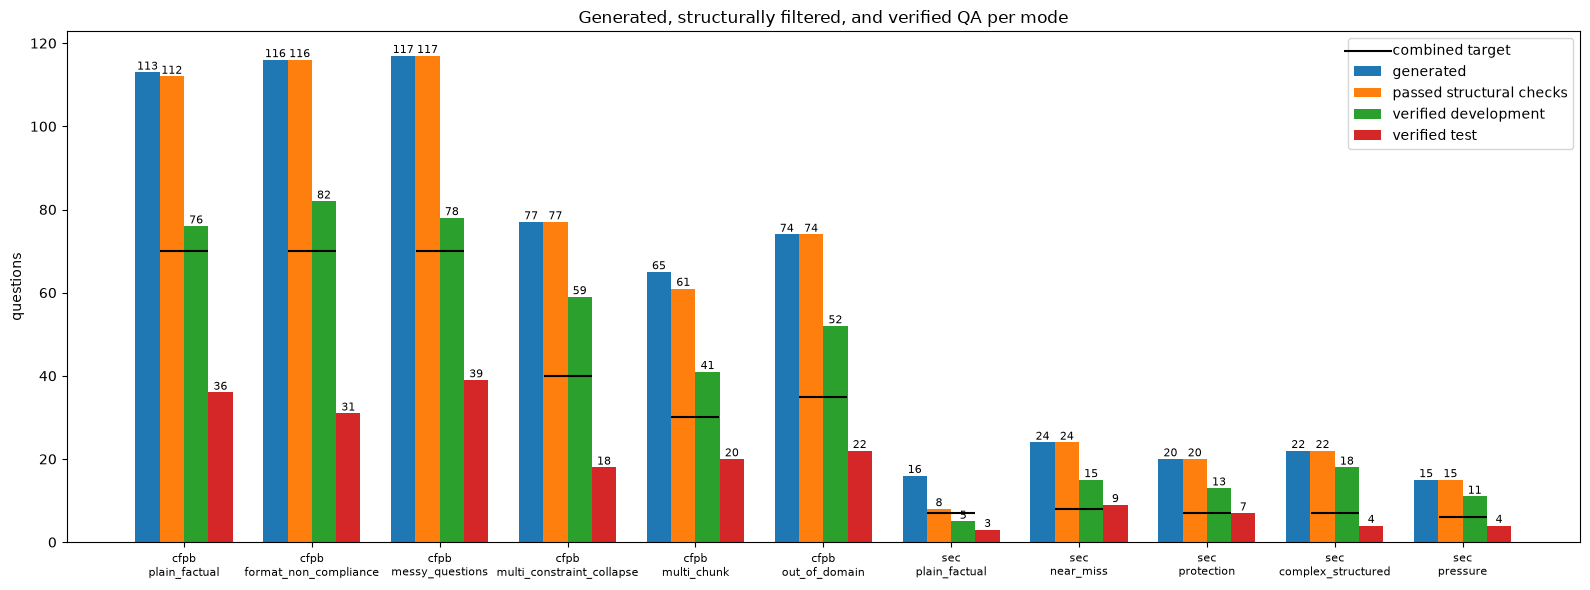

In [41]:
import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

# Reads saved outputs, so it works after a kernel restart (needs TOTAL_TARGETS and SDG_DIR)
RAW_PATH = SDG_DIR / "all_qa_raw.jsonl"
FILTERED_PATH = SDG_DIR / "all_qa_filtered.jsonl"
VERIFIED_PATH = SDG_DIR / "synthetic_qa_verified.jsonl"


def load_records(path):
    if not path.exists():
        return []
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


raw_records = load_records(RAW_PATH)
filtered_records = load_records(FILTERED_PATH)
verified_records = load_records(VERIFIED_PATH)
labels = [(document, mode) for document, mode_targets in TOTAL_TARGETS.items() for mode in mode_targets]
x = np.arange(len(labels))
width = 0.19
stage_counts = {
    "generated": Counter((r["document"], r["mode"]) for r in raw_records),
    "passed structural checks": Counter((r["document"], r["mode"]) for r in filtered_records),
    "verified development": Counter((r["document"], r["mode"]) for r in verified_records if r.get("split") == "development"),
    "verified test": Counter((r["document"], r["mode"]) for r in verified_records if r.get("split") == "test"),
}

fig, ax = plt.subplots(figsize=(16, 6))
for i, (stage, counts) in enumerate(stage_counts.items()):
    bars = ax.bar(x + (i - 1.5) * width, [counts[label] for label in labels], width, label=stage)
    ax.bar_label(bars, fontsize=8)
ax.scatter(
    x,
    [TOTAL_TARGETS[document][mode] for document, mode in labels],
    marker="_",
    s=1200,
    color="black",
    zorder=3,
    label="combined target",
)
ax.set_xticks(x, [f"{document}\n{mode}" for document, mode in labels], fontsize=8)
ax.set_ylabel("questions")
ax.set_title("Generated, structurally filtered, and verified QA per mode")
ax.legend()
plt.tight_layout()
plt.show()

In [42]:
import pandas as pd

checked_records = load_records(VERIFIED_PATH) + load_records(REJECTED_VERIFICATION_PATH)

# The flags of a record are the boolean fields the verifier returned, so each mode shows only its own flags
rows: dict[tuple[str, str, str], dict] = {}
flag_order: list[str] = []
for r in checked_records:
    row = rows.setdefault((r.get("split", "unassigned"), r["document"], r["mode"]), {"checked": 0, "verified": 0, "error": 0})
    row["checked"] += 1
    row["verified"] += bool(r["verified"])
    verdict = r.get("verification", {})
    if "error" in verdict:
        row["error"] += 1
        continue
    for flag, value in verdict.items():
        if isinstance(value, bool):
            if flag not in flag_order:
                flag_order.append(flag)
            row[flag] = row.get(flag, 0) + (value is False)  # count of records where the flag was false

flag_table = pd.DataFrame.from_dict(rows, orient="index")
if flag_table.empty:
    print("No verification results found in the saved files.")
else:
    flag_table.index = pd.MultiIndex.from_tuples(flag_table.index, names=["split", "document", "mode"])
    flag_table = flag_table.sort_index()
    flag_table.insert(2, "pass rate", (flag_table["verified"] / flag_table["checked"]).round(2))
    flag_table = flag_table[["checked", "verified", "pass rate", "error", *flag_order]]
    print("Flag columns: number of records where the flag was false. '-' means the flag is not checked for that mode.")
    display(flag_table.fillna("-"))

Flag columns: number of records where the flag was false. '-' means the flag is not checked for that mode.


checked  verified  pass rate  \
split       document mode                                                      
development cfpb     format_non_compliance           82        82        1.0   
                     messy_questions                 78        78        1.0   
                     multi_chunk                     41        41        1.0   
                     multi_constraint_collapse       59        59        1.0   
                     out_of_domain                   52        52        1.0   
                     plain_factual                   76        76        1.0   
            sec      complex_structured              18        18        1.0   
                     near_miss                       15        15        1.0   
                     plain_factual                    5         5        1.0   
                     pressure                        11        11        1.0   
                     protection                      13        13        1.0   
test        cfpb     format_non_compliance           31        31        1.0   
                     messy_questions                 39        39        1.0   
                     multi_chunk                     20        20        1.0   
                     multi_constraint_collapse       18        18        1.0   
                     out_of_domain                   22        22        1.0   
                     plain_factual                   36        36        1.0   
            sec      complex_structured               4         4        1.0   
                     near_miss                        9         9        1.0   
                     plain_factual                    3         3        1.0   
                     pressure                         4         4        1.0   
                     protection                       7         7        1.0   
unassigned  cfpb     format_non_compliance            3         0        0.0   

                                                error correct supported  \
split       document mode                                                 
development cfpb     format_non_compliance          0     0.0       0.0   
                     messy_questions                0     0.0       0.0   
                     multi_chunk                    0     0.0       0.0   
                     multi_constraint_collapse      0     0.0       0.0   
                     out_of_domain                  0       -         -   
                     plain_factual                  0     0.0       0.0   
            sec      complex_structured             0       -         -   
                     near_miss                      0       -         -   
                     plain_factual                  0       -         -   
                     pressure                       0       -         -   
                     protection                     0       -         -   
test        cfpb     format_non_compliance          0     0.0       0.0   
                     messy_questions                0     0.0       0.0   
                     multi_chunk                    0     0.0       0.0   
                     multi_constraint_collapse      0     0.0       0.0   
                     out_of_domain                  0       -         -   
                     plain_factual                  0     0.0       0.0   
            sec      complex_structured             0       -         -   
                     near_miss                      0       -         -   
                     plain_factual                  0       -         -   
                     pressure                       0       -         -   
                     protection                     0       -         -   
unassigned  cfpb     format_non_compliance          0     0.0       0.0   

                                               complete answerable  \
split       document mode                                            
development cfpb     format_non